### Import Dependencies

In [61]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
from pathlib import Path
import json
import sqlite3

### Set Path and Define Stages

In [62]:
RESULTS = Path("../results/benchmark_10-20-26")
STAGES  = {"decode", "preprocess", "encode", "project"}

### Combine CSV Stage Data
Data only using `perf_counter_ns()` and `cuda.Events`

In [63]:
def to_wide(long, run_name, stages=STAGES):
    return (
        long.pivot_table(index=["batch_size", "iter"], columns="stage",
                         values="duration_ms")
            .reindex(columns=[s for s in stages if s in set(long["stage"])])
            .rename(columns=lambda s: f"{s}_ms")
            .reset_index()
            .assign(run=run_name)
    )


def load_run(run_dir, stages=STAGES, wide=True):
    run_dir = Path(run_dir)

    frames = []
    for stage in stages:
        csv = run_dir / f"{stage}.csv"

        if not csv.exists():
            continue

        df = pd.read_csv(csv)
        df["stage"] = stage
        frames.append(df)

    long = pd.concat(frames, ignore_index=True)

    return to_wide(long, run_dir.name, stages) if wide else long.assign(run=run_dir.name)

In [64]:
nonsys_df = load_run(RESULTS / "nonsys_run")
nonsys_df.head(3)

stage,batch_size,iter,encode_ms,decode_ms,project_ms,preprocess_ms,run
0,1,0,336.575714,13.665998,1.445984,29.241159,nonsys_run
1,1,1,91.274239,10.903646,0.653568,23.717831,nonsys_run
2,1,2,49.300991,8.895795,2.484960,56.627042,nonsys_run


In [65]:
nsys_df = load_run(RESULTS / "nsys_run")
nsys_df.head(3)

stage,batch_size,iter,encode_ms,decode_ms,project_ms,preprocess_ms,run
0,1,0,375.531769,17.747797,2.783904,32.667117,nsys_run
1,1,1,86.360321,10.778701,0.642592,23.805649,nsys_run
2,1,2,44.357632,9.024347,0.645344,39.021963,nsys_run


### Read NSYS SQLite Data

In [66]:
nsys_db = RESULTS / "nsys_run" / "nsys_capture.sqlite"

QUERY = """
SELECT text AS name, start, end, globalTid
FROM NVTX_EVENTS
WHERE eventType = 59          -- NvtxPushPopRange
  AND text LIKE '%/bs=%'
ORDER BY start
"""

with sqlite3.connect(nsys_db) as conn:
    nvtx_df = pd.read_sql_query(QUERY, conn)

nvtx_df["duration_ms"] = (nvtx_df["end"] - nvtx_df["start"]) / 1e6

## Same name format as push() in run_nvidia.py: "<stage>/bs=<n>"
nvtx_df[["stage", "batch_size"]] = nvtx_df["name"].str.extract(r"^(\w+)/bs=(\d+)$")
nvtx_df["batch_size"] = nvtx_df["batch_size"].astype(int)

## iter = position within its (batch_size, stage) group, since the range name
## carries no index -- works because the rows are sorted by start
nvtx_df["iter"] = nvtx_df.groupby(["batch_size", "stage"]).cumcount()

nvtx_df.head(10)

,name,start,end,globalTid,duration_ms,stage,batch_size,iter
0,subtest/bs=1,7108916320,16363546944,285105449028937,9254.630624,subtest,1,0
1,iter/bs=1,7109018496,7537946432,285105449028937,428.927936,iter,1,0
2,decode/bs=1,7109023392,7126751232,285105449028937,17.727840,decode,1,0
3,preprocess/bs=1,7126789120,7159419424,285105449028937,32.630304,preprocess,1,0
4,encode/bs=1,7159459232,7505106656,285105449028937,345.647424,encode,1,0
5,project/bs=1,7505125504,7537937536,285105449028937,32.812032,project,1,0
6,iter/bs=1,7537985888,7612438720,285105449028937,74.452832,iter,1,1
7,decode/bs=1,7537995936,7548758656,285105449028937,10.762720,decode,1,1
8,preprocess/bs=1,7548793312,7572566688,285105449028937,23.773376,preprocess,1,1
9,encode/bs=1,7572598272,7611905568,285105449028937,39.307296,encode,1,1


In [67]:
## drops the iter/subtest wrapper ranges, at every batch size
nvtx_df = nvtx_df[nvtx_df["stage"].isin(STAGES)].copy()

nvtx_df.head(5)

,name,start,end,globalTid,duration_ms,stage,batch_size,iter
2,decode/bs=1,7109023392,7126751232,285105449028937,17.727840,decode,1,0
3,preprocess/bs=1,7126789120,7159419424,285105449028937,32.630304,preprocess,1,0
4,encode/bs=1,7159459232,7505106656,285105449028937,345.647424,encode,1,0
5,project/bs=1,7505125504,7537937536,285105449028937,32.812032,project,1,0
7,decode/bs=1,7537995936,7548758656,285105449028937,10.762720,decode,1,1


In [68]:
nvtx_wide = to_wide(nvtx_df, "nvtx")
nvtx_wide.head(3)

stage,batch_size,iter,encode_ms,decode_ms,project_ms,preprocess_ms,run
0,1,0,345.647424,17.72784,32.812032,32.630304,nvtx
1,1,1,39.307296,10.76272,0.511744,23.773376,nvtx
2,1,2,36.051936,9.00512,0.494496,38.986048,nvtx


### Compare Stages Across Runs
`nonsys_run` and `nsys_run` are `perf_counter_ns()`; `nvtx` is the NVTX range from the same capture as `nsys_run`.

In [69]:
WARMUP = 5

nonsys_warm = nonsys_df[nonsys_df["iter"] >= WARMUP]
nsys_warm   = nsys_df[nsys_df["iter"] >= WARMUP]
nvtx_warm   = nvtx_wide[nvtx_wide["iter"] >= WARMUP]

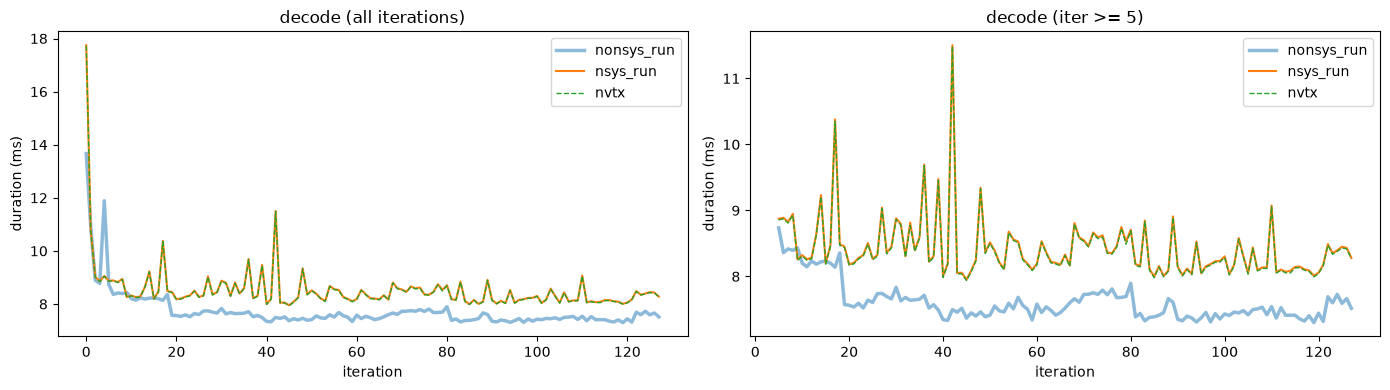

In [70]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))

ax1.plot(nonsys_df["iter"], nonsys_df["decode_ms"], label="nonsys_run", linewidth=2.5, alpha=0.5)
ax1.plot(nsys_df["iter"], nsys_df["decode_ms"], label="nsys_run", linewidth=1.5)
ax1.plot(nvtx_wide["iter"], nvtx_wide["decode_ms"], label="nvtx", linewidth=1.0, linestyle="--")
ax1.set_title("decode (all iterations)")

ax2.plot(nonsys_warm["iter"], nonsys_warm["decode_ms"], label="nonsys_run", linewidth=2.5, alpha=0.5)
ax2.plot(nsys_warm["iter"], nsys_warm["decode_ms"], label="nsys_run", linewidth=1.5)
ax2.plot(nvtx_warm["iter"], nvtx_warm["decode_ms"], label="nvtx", linewidth=1.0, linestyle="--")
ax2.set_title(f"decode (iter >= {WARMUP})")

for ax in (ax1, ax2):
    ax.set_xlabel("iteration")
    ax.set_ylabel("duration (ms)")
    ax.legend()

plt.tight_layout()
plt.show()

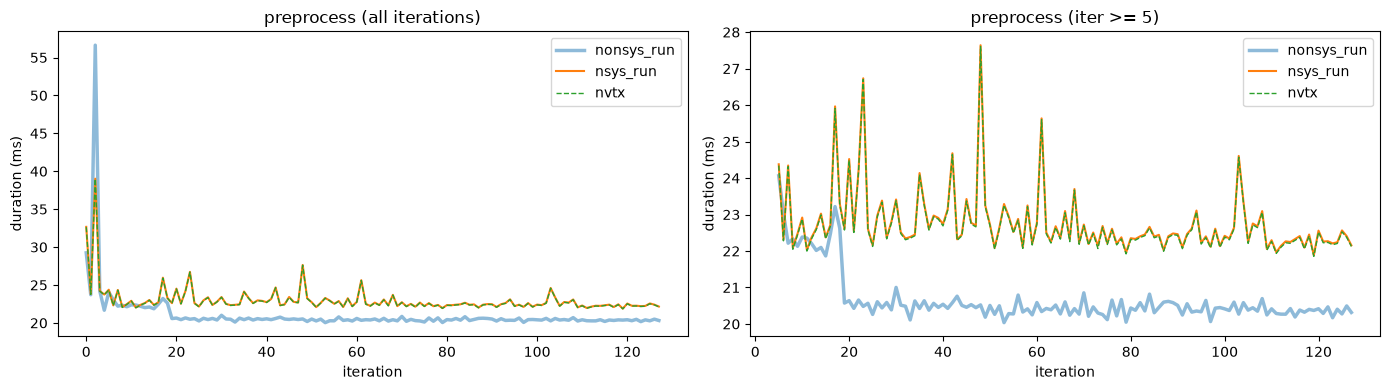

In [71]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))

ax1.plot(nonsys_df["iter"], nonsys_df["preprocess_ms"], label="nonsys_run", linewidth=2.5, alpha=0.5)
ax1.plot(nsys_df["iter"], nsys_df["preprocess_ms"], label="nsys_run", linewidth=1.5)
ax1.plot(nvtx_wide["iter"], nvtx_wide["preprocess_ms"], label="nvtx", linewidth=1.0, linestyle="--")
ax1.set_title("preprocess (all iterations)")

ax2.plot(nonsys_warm["iter"], nonsys_warm["preprocess_ms"], label="nonsys_run", linewidth=2.5, alpha=0.5)
ax2.plot(nsys_warm["iter"], nsys_warm["preprocess_ms"], label="nsys_run", linewidth=1.5)
ax2.plot(nvtx_warm["iter"], nvtx_warm["preprocess_ms"], label="nvtx", linewidth=1.0, linestyle="--")
ax2.set_title(f"preprocess (iter >= {WARMUP})")

for ax in (ax1, ax2):
    ax.set_xlabel("iteration")
    ax.set_ylabel("duration (ms)")
    ax.legend()

plt.tight_layout()
plt.show()

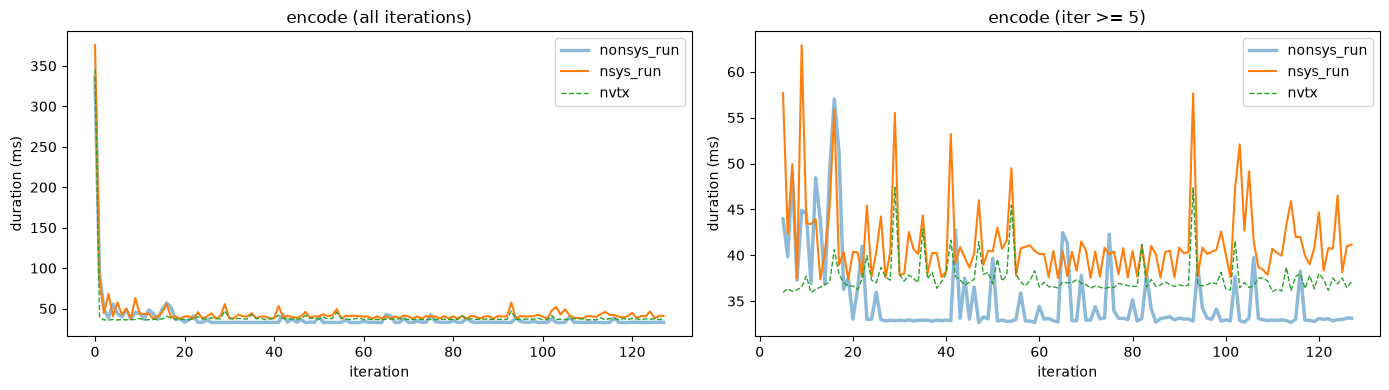

In [72]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))

ax1.plot(nonsys_df["iter"], nonsys_df["encode_ms"], label="nonsys_run", linewidth=2.5, alpha=0.5)
ax1.plot(nsys_df["iter"], nsys_df["encode_ms"], label="nsys_run", linewidth=1.5)
ax1.plot(nvtx_wide["iter"], nvtx_wide["encode_ms"], label="nvtx", linewidth=1.0, linestyle="--")
ax1.set_title("encode (all iterations)")

ax2.plot(nonsys_warm["iter"], nonsys_warm["encode_ms"], label="nonsys_run", linewidth=2.5, alpha=0.5)
ax2.plot(nsys_warm["iter"], nsys_warm["encode_ms"], label="nsys_run", linewidth=1.5)
ax2.plot(nvtx_warm["iter"], nvtx_warm["encode_ms"], label="nvtx", linewidth=1.0, linestyle="--")
ax2.set_title(f"encode (iter >= {WARMUP})")

for ax in (ax1, ax2):
    ax.set_xlabel("iteration")
    ax.set_ylabel("duration (ms)")
    ax.legend()

plt.tight_layout()
plt.show()

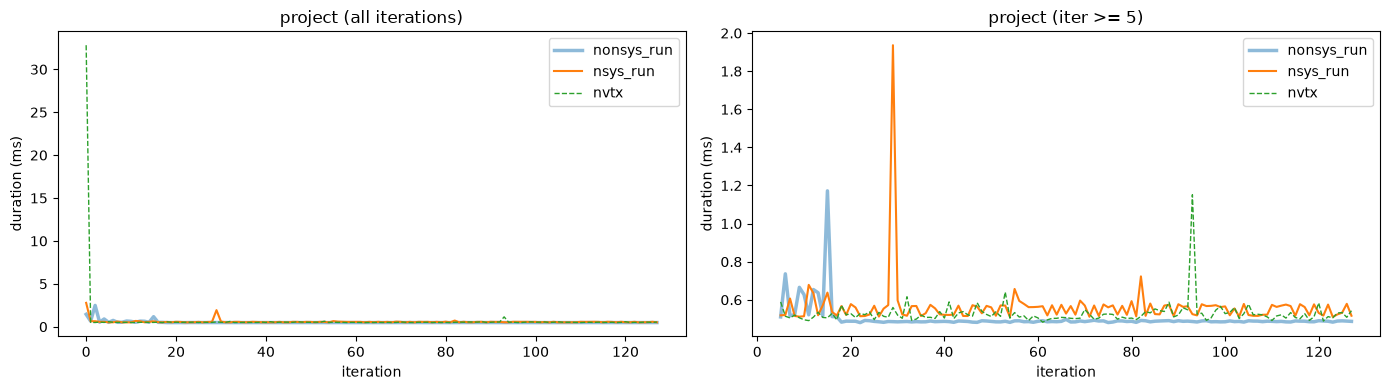

In [73]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))

ax1.plot(nonsys_df["iter"], nonsys_df["project_ms"], label="nonsys_run", linewidth=2.5, alpha=0.5)
ax1.plot(nsys_df["iter"], nsys_df["project_ms"], label="nsys_run", linewidth=1.5)
ax1.plot(nvtx_wide["iter"], nvtx_wide["project_ms"], label="nvtx", linewidth=1.0, linestyle="--")
ax1.set_title("project (all iterations)")

ax2.plot(nonsys_warm["iter"], nonsys_warm["project_ms"], label="nonsys_run", linewidth=2.5, alpha=0.5)
ax2.plot(nsys_warm["iter"], nsys_warm["project_ms"], label="nsys_run", linewidth=1.5)
ax2.plot(nvtx_warm["iter"], nvtx_warm["project_ms"], label="nvtx", linewidth=1.0, linestyle="--")
ax2.set_title(f"project (iter >= {WARMUP})")

for ax in (ax1, ax2):
    ax.set_xlabel("iteration")
    ax.set_ylabel("duration (ms)")
    ax.legend()

plt.tight_layout()
plt.show()

### Compute Metrics from Data

In [74]:
ORDER = ["decode", "preprocess", "encode", "project"]

summary = pd.concat([nonsys_warm, nsys_warm, nvtx_warm])
summary = (
    summary.melt(id_vars="run", value_vars=[f"{s}_ms" for s in ORDER],
                 var_name="stage", value_name="ms")
           .groupby(["stage", "run"])["ms"]
           .agg(median="median", p95=lambda s: s.quantile(0.95), min="min", std="std")
           .round(2)
)
summary


median    p95    min   std
stage         run                                   
decode_ms     nonsys_run    7.53   8.23   7.30  0.29
              nsys_run      8.30   9.07   7.95  0.46
              nvtx          8.29   9.06   7.94  0.46
encode_ms     nonsys_run   33.04  44.47  32.66  4.45
              nsys_run     40.41  51.87  37.35  4.55
              nvtx         37.01  41.45  35.92  1.90
preprocess_ms nonsys_run   20.45  22.35  20.04  0.71
              nsys_run     22.48  24.51  21.89  0.90
              nvtx         22.45  24.47  21.85  0.90
project_ms    nonsys_run    0.49   0.52   0.48  0.07
              nsys_run      0.56   0.61   0.51  0.13
              nvtx          0.52   0.58   0.48  0.06